# Poké-Catch · 01 · Análisis exploratorio de datos

**Técnica asignada:** clasificación.

**Problema.** Un jugador que lanza una Poké Ball no sabe si el lanzamiento va a funcionar. El resultado depende del Pokémon y de la situación del combate. Queremos predecir, para un intento de captura, si termina en **captura** o **no captura**.

**Este notebook:**

1. Documenta la procedencia de los datos.
2. Examina su estructura y calidad.
3. Explica qué representa cada registro y cómo se construye.
4. Identifica patrones relevantes para el problema.
5. Justifica las decisiones de limpieza, transformación y selección de variables.
6. Comprueba que los datos sirven para clasificación y declara sus limitaciones.

El experimento con modelos está en `02_experimento_comparativo.ipynb`.

## 0. Configuración

In [1]:
import sys
from pathlib import Path

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pokecatch.py").exists())
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

import pokecatch as pc

plt.rcParams.update(pc.ESTILO)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)
AZUL, NARANJA, GRIS = pc.AZUL, pc.NARANJA, pc.GRIS

## 1. Procedencia de los datos

| | |
|---|---|
| **Fuente** | [PokeAPI](https://pokeapi.co), base de datos abierta con la información de los juegos principales de Pokémon |
| **Origen exacto** | Archivos CSV del repositorio oficial: <https://github.com/PokeAPI/pokeapi/tree/master/data/v2/csv> |
| **Fecha de descarga** | 14 de noviembre de 2026 |
| **Cobertura** | 1025 especies, generaciones 1 a 9 |
| **Copia local** | `datos/raw/` (9 archivos, 250 KB). Se pueden volver a descargar con `python src/descargar_datos.py` |

PokeAPI describe a las **especies**, pero no existe un registro público de **lanzamientos reales** de Poké Balls. Por eso el dataset de intentos se genera a partir de estos datos y de la fórmula de captura oficial de los juegos (sección 4).

In [2]:
tablas = pc.cargar_crudos()
descripcion = {
    "pokemon_species": "Una fila por especie: ratio de captura, crianza, evolución, rareza",
    "pokemon": "Una fila por forma (incluye megas y formas regionales): peso, altura, experiencia",
    "pokemon_stats": "Estadísticas base, en formato largo (6 filas por forma)",
    "stats": "Nombres de las estadísticas",
    "pokemon_types": "Tipos de cada forma (1 o 2 filas por forma)",
    "types": "Nombres de los tipos",
    "pokemon_egg_groups": "Grupos huevo de cada especie",
    "egg_groups": "Nombres de los grupos huevo",
    "growth_rates": "Ritmos de crecimiento",
}
pd.DataFrame([{"tabla": t, "filas": len(df), "columnas": df.shape[1],
               "celdas vacías": int(df.isna().sum().sum()), "filas duplicadas": int(df.duplicated().sum()),
               "contenido": descripcion[t]} for t, df in tablas.items()]).set_index("tabla")

,filas,columnas,celdas vacías,filas duplicadas,contenido
tabla,,,,,
pokemon_species,1025,20,2005,0,"Una fila por especie: ratio de captura, crianza, evolución, rareza"
pokemon,1351,8,188,0,"Una fila por forma (incluye megas y formas regionales): peso, altura, experiencia"
pokemon_stats,8106,4,0,0,"Estadísticas base, en formato largo (6 filas por forma)"
stats,9,5,6,0,Nombres de las estadísticas
pokemon_types,2116,3,0,0,Tipos de cada forma (1 o 2 filas por forma)
types,21,4,4,0,Nombres de los tipos
pokemon_egg_groups,1304,2,0,0,Grupos huevo de cada especie
egg_groups,15,2,0,0,Nombres de los grupos huevo
growth_rates,6,3,0,0,Ritmos de crecimiento


## 2. Estructura y calidad de los datos de origen

Revisamos las dos tablas principales: `pokemon_species` y `pokemon`.

In [3]:
sp = tablas["pokemon_species"]
print("pokemon_species:", sp.shape)
print("\nColumnas con valores faltantes:")
faltantes = sp.isna().sum()
print(faltantes[faltantes > 0].to_frame("faltantes").assign(pct=lambda d: (100 * d.faltantes / len(sp)).round(1)).to_string())
print("\nIdentificadores repetidos:", sp.identifier.duplicated().sum())
print("Rango de capture_rate:", sp.capture_rate.min(), "a", sp.capture_rate.max())
sp.head(3)

pokemon_species: (1025, 20)

Columnas con valores faltantes:
                         faltantes   pct
evolves_from_species_id        541  52.8
habitat_id                     639  62.3
conquest_order                 825  80.5

Identificadores repetidos: 0
Rango de capture_rate: 3 a 255


,id,identifier,generation_id,evolves_from_species_id,evolution_chain_id,color_id,shape_id,habitat_id,gender_rate,capture_rate,base_happiness,is_baby,hatch_counter,has_gender_differences,growth_rate_id,forms_switchable,is_legendary,is_mythical,order,conquest_order
0,1,bulbasaur,1,NaN,1,5,8,3.0,1,45,70,0,20,0,4,0,0,0,1,NaN
1,2,ivysaur,1,1.0,1,5,8,3.0,1,45,70,0,20,0,4,0,0,0,2,NaN
2,3,venusaur,1,2.0,1,5,8,3.0,1,45,70,0,20,1,4,1,0,0,3,NaN


In [4]:
pk = tablas["pokemon"]
print("pokemon:", pk.shape)
print("Formas por defecto:", int((pk.is_default == 1).sum()), "| formas alternativas:", int((pk.is_default == 0).sum()))
print("base_experience faltante: total", int(pk.base_experience.isna().sum()),
      "| en formas por defecto:", int(pk[pk.is_default == 1].base_experience.isna().sum()))
print("Peso o altura en cero o negativos:", int(((pk.weight <= 0) | (pk.height <= 0)).sum()))
print("Especies sin grupo huevo:", int((~sp.id.isin(tablas["pokemon_egg_groups"].species_id)).sum()))

pokemon: (1351, 8)
Formas por defecto: 1025 | formas alternativas: 326
base_experience faltante: total 49 | en formas por defecto: 0
Peso o altura en cero o negativos: 1
Especies sin grupo huevo: 0


**Lo que encontramos:**

- **No hay filas duplicadas** ni identificadores repetidos.
- `habitat_id` falta en **639 de 1025 especies (62 %)**. PokeAPI solo lo registra hasta la Gen 3.
- `conquest_order` falta en el 80 %: pertenece a un juego derivado y no describe al Pokémon.
- `evolves_from_species_id` falta en 541 especies. **No es un error**: son las especies básicas, que no evolucionan de nadie. El vacío es información.
- La tabla `pokemon` tiene 1351 formas para 1025 especies. Las 326 formas alternativas son megaevoluciones, formas regionales y similares. `base_experience` solo falta en formas alternativas.
- El ratio de captura está definido **por especie**, no por forma.
- Peso y altura vienen en hectogramos y decímetros. Hay una sola forma con peso y altura en cero (Eternatus Eternamax), y es una forma alternativa.

### Decisiones de limpieza

| Decisión | Justificación |
|---|---|
| Trabajar con una fila por **especie**, usando su **forma por defecto** | El ratio de captura es de la especie. Así evitamos repetir especies, y desaparecen los 49 vacíos de `base_experience` y la forma con peso cero |
| Descartar `habitat_id` | Falta en el 62 % y de forma sistemática (todas las generaciones nuevas). Imputarlo sería inventar datos |
| Descartar `conquest_order`, `color_id`, `shape_id`, `order` | No describen la dificultad de captura o son identificadores internos |
| Mantener el vacío de `evolves_from_species_id` | Se transforma en variables de evolución (etapa, si es básico) |
| Convertir peso a kg y altura a m | Unidades legibles |

## 3. Características de cada especie

`pc.construir_especies()` (en `src/pokecatch.py`) aplica las decisiones anteriores y deja una fila por especie.

| Grupo | Variables | Cómo se obtienen |
|---|---|---|
| Poder | 6 estadísticas base, suma (`bst`), `base_experience` | Tabla larga de stats pasada a columnas |
| Rareza | `is_legendary`, `is_mythical`, `is_baby`, `es_ultraente` | Indicadores de PokeAPI; ultraentes por lista |
| Evolución | `etapa_evolutiva`, `es_final`, `etapas_restantes`, `especies_en_cadena`, `sin_evolucion` | Recorriendo `evolves_from_species_id` |
| Crianza | `exp_nivel_100`, `hatch_counter`, `sin_genero`, `pct_hembra`, `base_happiness`, grupos huevo | `gender_rate` en octavos pasa a % hembra; −1 significa sin género |
| Morfología | `peso_kg`, `altura_m` | Conversión de unidades |
| Diseño | 18 tipos (one-hot), `n_tipos`, `generation_id` | Un Pokémon puede tener dos tipos |

In [5]:
especies = pc.construir_especies(tablas)
print(especies.shape, "| valores faltantes en variables candidatas:",
      int(especies.drop(columns=["evolves_from_species_id"]).isna().sum().sum()))
especies[["identifier", "bst", "base_experience", "etapa_evolutiva", "es_final", "is_legendary",
          "hatch_counter", "pct_hembra", "peso_kg", "altura_m", "capture_rate"]].sample(6, random_state=7)

(1025, 73) | valores faltantes en variables candidatas: 0


,identifier,bst,base_experience,etapa_evolutiva,es_final,is_legendary,hatch_counter,pct_hembra,peso_kg,altura_m,capture_rate
571,minccino,300,60.0,1,0,0,15,0.750,5.8,0.4,255
146,dratini,300,60.0,1,0,0,40,0.500,3.3,1.8,45
361,glalie,480,168.0,2,1,0,20,0.500,256.5,1.5,75
747,toxapex,495,173.0,2,1,0,20,0.500,14.5,0.7,75
396,staravia,340,119.0,2,0,0,15,0.500,15.5,0.6,120
656,frogadier,405,142.0,2,0,0,20,0.125,10.9,0.6,45


### 3.1 Peso y altura: distribuciones muy asimétricas

Unos pocos Pokémon enormes estiran la escala. En escala logarítmica las distribuciones quedan simétricas.

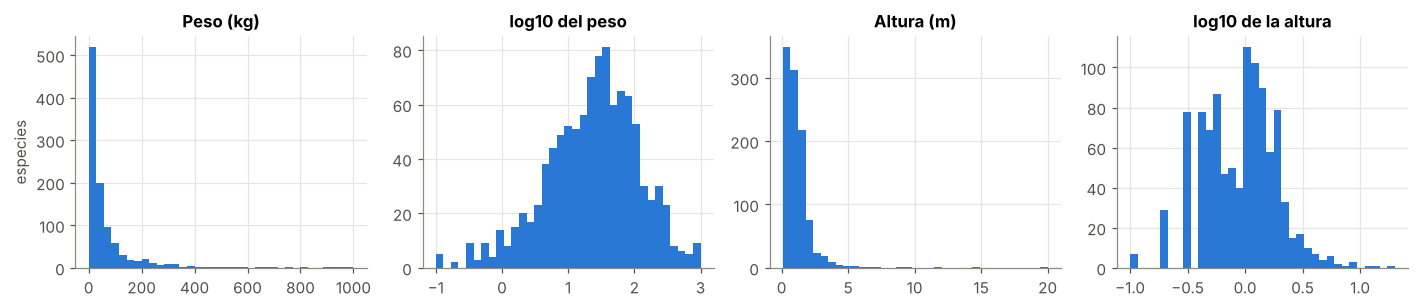

Asimetría: {'peso_kg': 4.34, 'log_peso': -0.47, 'altura_m': 6.56, 'log_altura': 0.0}

Índice peso/altura², los 3 mayores:
identifier  peso_kg  altura_m     imc
   cosmoem    999.9       0.1 99990.0
    minior     40.0       0.3   444.4
      aron     60.0       0.4   375.0


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(13, 2.9))
for ax, col, tit in [(axes[0], "peso_kg", "Peso (kg)"), (axes[1], "log_peso", "log10 del peso"),
                     (axes[2], "altura_m", "Altura (m)"), (axes[3], "log_altura", "log10 de la altura")]:
    ax.hist(especies[col], bins=35, color=AZUL)
    ax.set(title=tit, ylabel="especies" if ax is axes[0] else "")
plt.tight_layout(); plt.show()
print("Asimetría:", especies[["peso_kg", "log_peso", "altura_m", "log_altura"]].skew().round(2).to_dict())
print("\nÍndice peso/altura², los 3 mayores:")
print(especies.nlargest(3, "imc")[["identifier", "peso_kg", "altura_m", "imc"]].round(1).to_string(index=False))

**Decisión de transformación:** usar `log_peso` y `log_altura` en lugar de los valores crudos. El índice peso/altura² se descarta: tiene valores extremos sin sentido (Cosmoem, 999,9 kg en 10 cm) y en logaritmo es solo una combinación de las otras dos.

### 3.2 El ratio de captura: la variable oculta

`capture_rate` (3 a 255) es el número que los diseñadores asignaron a cada especie. Mientras más alto, más fácil de capturar. **No será una variable del modelo**: se usa solo para generar la clase. Si el modelo lo viera, bastaría aplicar la fórmula y no habría nada que aprender.

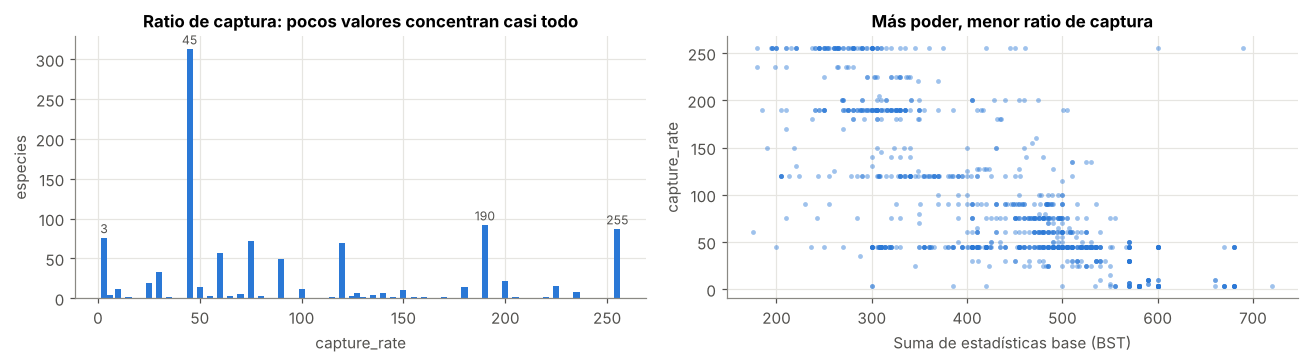

El 30,5 % de las especies tiene ratio 45. Correlación de Spearman BST–ratio: -0.73


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
vc = especies.capture_rate.value_counts().sort_index()
axes[0].bar(vc.index, vc.values, width=3, color=AZUL)
for v in [3, 45, 190, 255]:
    axes[0].annotate(f"{v}", (v, vc[v]), textcoords="offset points", xytext=(0, 3), ha="center", fontsize=8, color="#52514e")
axes[0].set(title="Ratio de captura: pocos valores concentran casi todo", xlabel="capture_rate", ylabel="especies")

axes[1].scatter(especies.bst, especies.capture_rate, s=10, color=AZUL, alpha=0.45, linewidths=0)
axes[1].set(title="Más poder, menor ratio de captura", xlabel="Suma de estadísticas base (BST)", ylabel="capture_rate")
plt.tight_layout(); plt.show()
print(f"El 30,5 % de las especies tiene ratio 45. Correlación de Spearman BST–ratio: "
      f"{especies[['bst', 'capture_rate']].corr(method='spearman').iloc[0, 1]:.2f}")

## 4. Construcción de los registros: una fila = un intento de captura

Como en el dataset de pingüinos, donde cada fila es un pingüino descrito por sus medidas, aquí **cada fila es un intento de captura**. La fila describe al Pokémon y al lanzamiento, y su clase es el resultado.

Para cada una de las 1025 especies se simulan **40 intentos**. En cada uno se sortea el contexto:

| Variable | Cómo se sortea |
|---|---|
| `hp_pct` | HP restante del rival, entero uniforme de 1 a 100 |
| `estado` | Ninguno 60 %, paralizado 15 %, dormido 12 %, envenenado 5 %, quemado 5 %, congelado 3 % |
| `ball` | Una de 8 balls con igual probabilidad |
| `turno` | Entero uniforme de 1 a 10 |
| `noche_o_cueva` | Sí en el 35 % de los intentos |

Luego la **fórmula oficial** (Gen V en adelante) calcula la probabilidad real:

$$a = \frac{(3\,HP_{max} - 2\,HP_{actual}) \cdot \text{ratio} \cdot \text{bonus}_{ball}}{3\,HP_{max}} \cdot \text{bonus}_{estado} \qquad P = \left(\frac{1}{(255/a)^{3/16}}\right)^{4}$$

con $P = 1$ si $a \ge 255$. La clase se sortea con esa probabilidad, igual que hace el juego.

| Ball | Multiplicador | Condición |
|---|---|---|
| Poké / Super / Ultra | ×1 / ×1,5 / ×2 | Siempre |
| Malla | ×3,5 | Tipo agua o bicho (si no, ×1) |
| Rápida | ×4 | Velocidad base ≥ 100 (si no, ×1) |
| Ocaso | ×3 | Noche o cueva (si no, ×1) |
| Veloz | ×5 | Turno 1 (si no, ×1) |
| Turno | ×(1 + 0,3·(turno − 1)), máximo ×4 | Crece con los turnos |

Estado: dormido o congelado ×2,5; paralizado, envenenado o quemado ×1,5. Con un ultraente, estas balls valen ×0,1.

La simulación usa una semilla fija, así que siempre produce los mismos registros.

In [8]:
intentos = pc.simular_intentos(especies)            # 41 000 filas, semilla fija
pc.DIR_PROC.mkdir(parents=True, exist_ok=True)
especies.to_csv(pc.DIR_PROC / "especies.csv", index=False, encoding="utf-8")
intentos.to_csv(pc.DIR_PROC / "intentos.csv", index=False, encoding="utf-8")

datos = pc.unir(especies, intentos)
datos["clase"] = datos.captura.map({1: "captura", 0: "no captura"})
print(f"{len(datos):,} registros × {datos.shape[1]} columnas | faltantes: {int(datos.isna().sum().sum())} | "
      f"filas duplicadas: {int(datos.duplicated().sum())}")

41,000 registros × 71 columnas | faltantes: 0 | filas duplicadas: 16


Hay 16 filas idénticas a otra. No son errores de carga: son intentos independientes sobre la misma especie que coincidieron en contexto y resultado, algo esperable con 40 intentos por especie. **Se mantienen**, porque cada una es un intento distinto.

### 4.1 Cómo se lee una fila

In [9]:
datos[["identifier", "bst", "etapa_evolutiva", "is_legendary", "log_peso", "st_speed",
       "hp_pct", "estado", "ball", "turno", "noche_o_cueva", "clase"]].sample(8, random_state=11).reset_index(drop=True)

,identifier,bst,etapa_evolutiva,is_legendary,log_peso,st_speed,hp_pct,estado,ball,turno,noche_o_cueva,clase
0,glimmet,350,1,0,0.903090,60,12,ninguno,Super Ball,9,1,no captura
1,eelektrik,405,2,0,1.342423,40,64,envenenado,Malla Ball,6,0,no captura
2,landorus,600,1,1,1.832509,101,46,ninguno,Turno Ball,1,0,no captura
3,electrike,295,1,0,1.181844,65,16,ninguno,Super Ball,7,1,captura
4,samurott,528,3,0,1.975891,70,30,ninguno,Malla Ball,10,0,no captura
5,metapod,205,2,0,0.995635,30,67,envenenado,Malla Ball,4,0,captura
6,magneton,465,2,0,1.778151,70,11,ninguno,Malla Ball,4,0,no captura
7,entei,580,1,1,2.296665,100,44,ninguno,Ultra Ball,3,1,no captura


La primera fila se lee así: *un intento de capturar a ese Pokémon, con ese poder y esa etapa evolutiva, cuando le quedaba ese porcentaje de HP, con ese estado, usando esa ball en ese turno; el resultado fue esa clase.*

### 4.2 Distribución de la clase

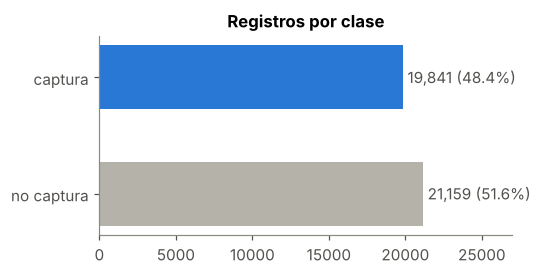

In [10]:
conteo = datos.clase.value_counts().reindex(["no captura", "captura"])
fig, ax = plt.subplots(figsize=(5, 2.6))
ax.barh(conteo.index, conteo.values, color=[GRIS, AZUL], height=0.55)
for i, v in enumerate(conteo.values):
    ax.text(v + 300, i, f"{v:,} ({v / len(datos):.1%})", va="center", color="#52514e")
ax.set(title="Registros por clase", xlim=(0, 27000)); ax.grid(False)
plt.tight_layout(); plt.show()

Las clases están **casi balanceadas** (48,4 % captura y 51,6 % no captura), pero no son idénticas. Por eso en el experimento usaremos una medida agregada que trate a las dos clases por igual (F1 macro) y no solo la exactitud.

## 5. Patrones relevantes

### 5.1 Variables del lanzamiento

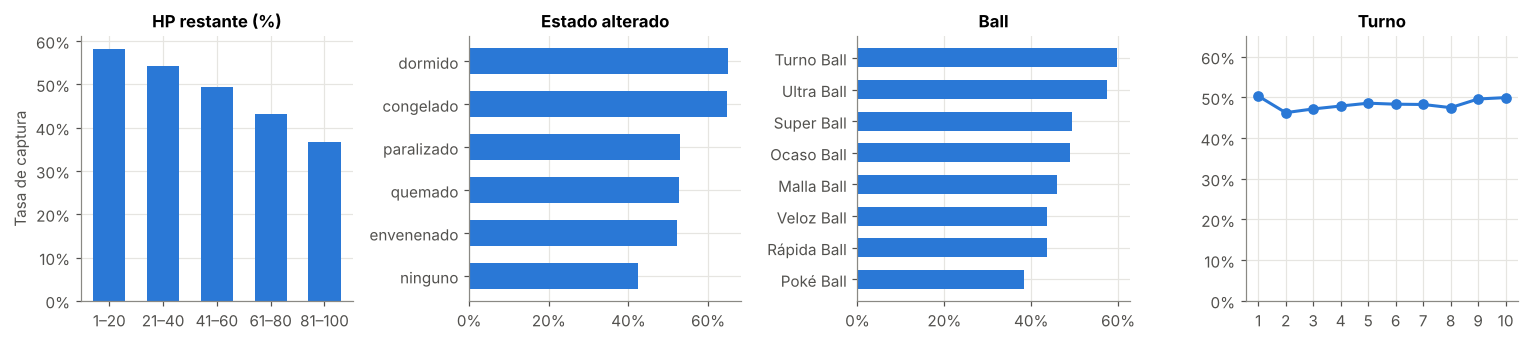

In [11]:
tasa = lambda col: datos.groupby(col, observed=True).captura.mean()
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))

g = tasa(pd.cut(datos.hp_pct, [0, 20, 40, 60, 80, 100], labels=["1–20", "21–40", "41–60", "61–80", "81–100"]))
axes[0].bar(g.index.astype(str), g.values, color=AZUL, width=0.6)
axes[0].set(title="HP restante (%)", ylabel="Tasa de captura")

g = tasa("estado").sort_values()
axes[1].barh(g.index, g.values, color=AZUL, height=0.6); axes[1].set(title="Estado alterado")

g = tasa("ball").sort_values()
axes[2].barh(g.index, g.values, color=AZUL, height=0.6); axes[2].set(title="Ball")

g = tasa("turno")
axes[3].plot(g.index, g.values, "o-", color=AZUL, lw=2); axes[3].set(title="Turno", ylim=(0, 0.65), xticks=range(1, 11))

for ax in [axes[0], axes[3]]:
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
for ax in [axes[1], axes[2]]:
    ax.xaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout(); plt.show()

- **HP:** menos HP, más capturas (58 % con el rival bajo 20 % de HP y 37 % sobre 80 %).
- **Estado:** dormido y congelado son los más efectivos. Paralizado, envenenado y quemado rinden igual entre sí.
- **Ball:** la Poké Ball es la peor. Malla, Veloz, Rápida y Ocaso quedan *en promedio* bajo la Ultra Ball, porque solo rinden cuando se cumple su condición.
- **Turno:** por sí solo casi no cambia la tasa de captura. Importa solo en combinación con la Veloz Ball y la Turno Ball.

### 5.2 Las balls especiales dependen de una condición

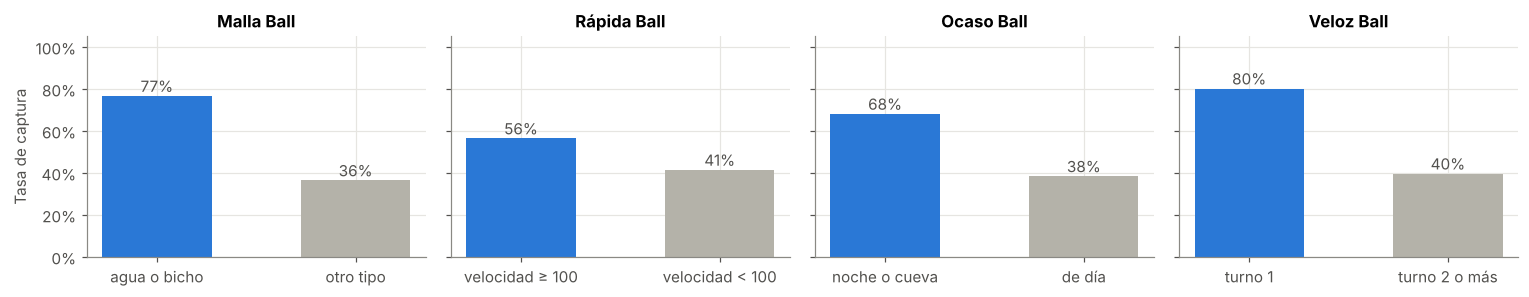

In [12]:
casos = [
    ("Malla Ball", (datos.tipo_water + datos.tipo_bug > 0), "agua o bicho", "otro tipo"),
    ("Rápida Ball", datos.st_speed >= 100, "velocidad ≥ 100", "velocidad < 100"),
    ("Ocaso Ball", datos.noche_o_cueva == 1, "noche o cueva", "de día"),
    ("Veloz Ball", datos.turno == 1, "turno 1", "turno 2 o más"),
]
fig, axes = plt.subplots(1, 4, figsize=(14, 2.8), sharey=True)
for ax, (ball, cond, si, no) in zip(axes, casos):
    sub = datos[datos.ball == ball]
    vals = [sub[cond[sub.index]].captura.mean(), sub[~cond[sub.index]].captura.mean()]
    ax.bar([si, no], vals, color=[AZUL, GRIS], width=0.55)
    for i, v in enumerate(vals):
        ax.text(i, v + 0.02, f"{v:.0%}", ha="center", color="#52514e")
    ax.set(title=ball, ylim=(0, 1.05)); ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylabel("Tasa de captura")
plt.tight_layout(); plt.show()

Cada ball especial rinde muy distinto según se cumpla su condición. Esto es una **interacción** entre variables (ball × tipo, ball × velocidad, ball × turno) que un modelo tiene que descubrir por su cuenta con pocos ejemplos de cada combinación.

**Decisión de transformación (se pone a prueba en el experimento):** agregar la variable `multiplicador_ball`, que es el multiplicador público de la ball en ese contexto. Las reglas de las balls son conocidas por cualquier jugador, a diferencia del ratio de captura. El experimento compara los modelos **con y sin** esta variable.

### 5.3 Variables del Pokémon

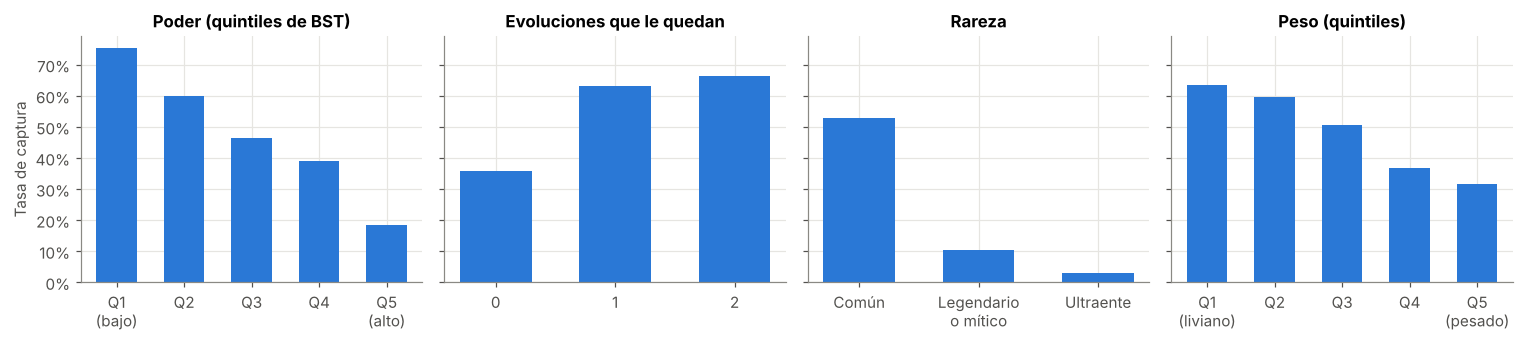

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)

g = tasa(pd.qcut(datos.bst, 5, labels=["Q1\n(bajo)", "Q2", "Q3", "Q4", "Q5\n(alto)"]))
axes[0].bar(g.index.astype(str), g.values, color=AZUL, width=0.6); axes[0].set(title="Poder (quintiles de BST)", ylabel="Tasa de captura")

g = tasa(datos.etapas_restantes.map({0: "0", 1: "1", 2: "2"}))
axes[1].bar(g.index, g.values, color=AZUL, width=0.6); axes[1].set(title="Evoluciones que le quedan")

rareza = np.select([datos.is_legendary + datos.is_mythical > 0, datos.es_ultraente == 1], ["Legendario\no mítico", "Ultraente"], "Común")
g = tasa(rareza).reindex(["Común", "Legendario\no mítico", "Ultraente"])
axes[2].bar(g.index, g.values, color=AZUL, width=0.6); axes[2].set(title="Rareza")

g = tasa(pd.qcut(datos.log_peso, 5, labels=["Q1\n(liviano)", "Q2", "Q3", "Q4", "Q5\n(pesado)"]))
axes[3].bar(g.index.astype(str), g.values, color=AZUL, width=0.6); axes[3].set(title="Peso (quintiles)")

axes[0].yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout(); plt.show()

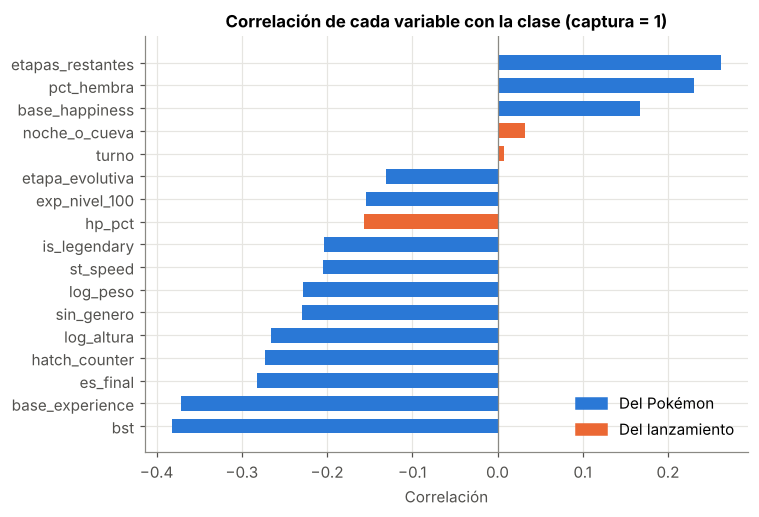

In [14]:
numericas = ["bst", "base_experience", "hatch_counter", "exp_nivel_100", "etapas_restantes", "etapa_evolutiva",
             "es_final", "is_legendary", "sin_genero", "pct_hembra", "base_happiness", "st_speed",
             "log_peso", "log_altura", "hp_pct", "turno", "noche_o_cueva"]
corr = datos[numericas].corrwith(datos.captura).sort_values()
del_lanzamiento = {"hp_pct", "turno", "noche_o_cueva"}

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.barh(corr.index, corr.values, color=[NARANJA if v in del_lanzamiento else AZUL for v in corr.index], height=0.65)
ax.axvline(0, color="#8a8984", lw=0.8)
ax.set(title="Correlación de cada variable con la clase (captura = 1)", xlabel="Correlación")
ax.legend(handles=[plt.matplotlib.patches.Patch(color=AZUL, label="Del Pokémon"),
                   plt.matplotlib.patches.Patch(color=NARANJA, label="Del lanzamiento")], frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

- **Poder:** es el patrón más fuerte. El quintil más débil se captura el 75 % de las veces y el más fuerte, el 19 %.
- **Evolución:** los Pokémon a los que les quedan evoluciones se capturan más.
- **Rareza:** legendarios y ultraentes casi nunca se capturan.
- **Crianza:** más ciclos de eclosión y crecimiento lento van con menos capturas; más proporción de hembras, con más capturas.
- **Peso y altura:** tienen relación con la clase, pero más débil que el poder, y en parte la heredan de él (los Pokémon grandes suelen ser fuertes).

### 5.4 Variables redundantes

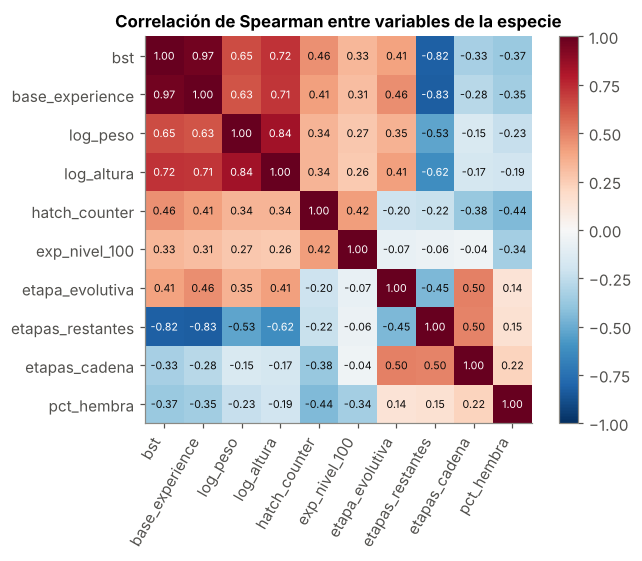

etapas_cadena = etapa_evolutiva + etapas_restantes en todas las especies: True


In [15]:
cols = ["bst", "base_experience", "log_peso", "log_altura", "hatch_counter", "exp_nivel_100",
        "etapa_evolutiva", "etapas_restantes", "etapas_cadena", "pct_hembra"]
m = especies[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(m, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=60, ha="right"); ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{m.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(m.iloc[i, j]) > 0.6 else "#0b0b0b")
ax.set_title("Correlación de Spearman entre variables de la especie"); ax.grid(False)
plt.colorbar(im, fraction=0.045); plt.tight_layout(); plt.show()
print("etapas_cadena = etapa_evolutiva + etapas_restantes en todas las especies:",
      bool((especies.etapas_cadena == especies.etapa_evolutiva + especies.etapas_restantes).all()))

- `bst` y `base_experience` están casi perfectamente correlacionadas (0,97). Se mantienen ambas: los modelos de árboles no se ven afectados y la regresión logística usa regularización.
- `log_peso` y `log_altura` también se parecen (0,84), pero describen cosas distintas.
- `etapas_cadena` es exactamente la suma de otras dos variables: se descarta.

## 6. Decisiones de selección de variables

| Variable | Decisión | Justificación |
|---|---|---|
| `capture_rate`, `p_real` | **Fuera** | Generan la clase. Usarlas sería fuga de información |
| `species_id`, `identifier`, `evolution_chain_id` | **Fuera** | Identificadores. El modelo memorizaría especies en vez de aprender de sus características. La cadena evolutiva se usa solo para separar los datos |
| `habitat_id` | **Fuera** | Falta en el 62 % |
| `generation_id` | **Fuera** | No describe al Pokémon, y una especie nueva tendría un valor nunca visto |
| `peso_kg`, `altura_m`, `imc` | **Fuera** | Reemplazadas por `log_peso` y `log_altura` |
| `etapas_cadena` | **Fuera** | Combinación exacta de otras dos |
| Poder, rareza, evolución, crianza, tipos, grupos huevo | **Dentro** | Describen al Pokémon y muestran relación con la clase |
| `hp_pct`, `estado`, `ball`, `turno`, `noche_o_cueva` | **Dentro** | Describen el lanzamiento; `estado` y `ball` pasan a one-hot |
| `multiplicador_ball` | **A prueba** | Se compara en el experimento (sección 5.2) |

In [16]:
VE = pc.variables_especie(especies)
VL = list(pc.variables_lanzamiento(datos).columns)
print(f"Variables del Pokémon: {len(VE)}\n{VE}\n")
print(f"Variables del lanzamiento: {len(VL)}\n{VL}")

Variables del Pokémon: 58
['st_hp', 'st_attack', 'st_defense', 'st_special_attack', 'st_special_defense', 'st_speed', 'bst', 'base_experience', 'is_legendary', 'is_mythical', 'is_baby', 'es_ultraente', 'etapa_evolutiva', 'es_final', 'etapas_restantes', 'especies_en_cadena', 'sin_evolucion', 'exp_nivel_100', 'hatch_counter', 'sin_genero', 'pct_hembra', 'base_happiness', 'log_altura', 'log_peso', 'n_tipos', 'tipo_bug', 'tipo_dark', 'tipo_dragon', 'tipo_electric', 'tipo_fairy', 'tipo_fighting', 'tipo_fire', 'tipo_flying', 'tipo_ghost', 'tipo_grass', 'tipo_ground', 'tipo_ice', 'tipo_normal', 'tipo_poison', 'tipo_psychic', 'tipo_rock', 'tipo_steel', 'tipo_water', 'huevo_bug', 'huevo_ditto', 'huevo_dragon', 'huevo_fairy', 'huevo_flying', 'huevo_ground', 'huevo_humanshape', 'huevo_indeterminate', 'huevo_mineral', 'huevo_monster', 'huevo_no_eggs', 'huevo_plant', 'huevo_water1', 'huevo_water2', 'huevo_water3']

Variables del lanzamiento: 17
['hp_pct', 'turno', 'noche_o_cueva', 'estado_ninguno',

## 7. ¿Sirven estos datos para clasificación?

Un proyecto de clasificación necesita casos con categorías conocidas. Aquí cada registro tiene su clase, hay 41 000 casos, las dos clases están casi balanceadas y las variables muestran relación con la clase.

Hay una particularidad importante: **la clase tiene azar**. Dos intentos idénticos pueden terminar distinto, igual que en el juego.

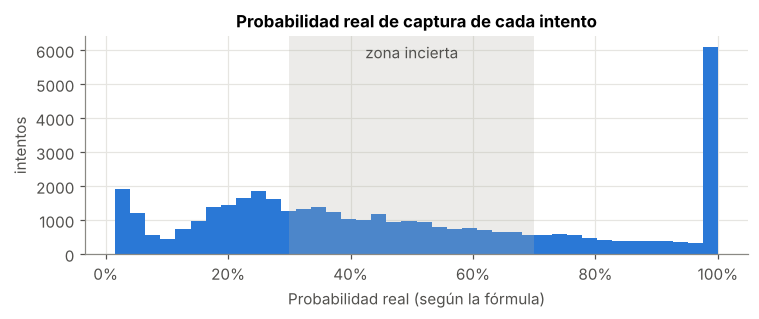

Intentos con probabilidad real entre 30 % y 70 %: 37.6%
Intentos con captura segura (P = 100 %): 14.0%
Exactitud máxima posible conociendo la probabilidad real: 76.8%


In [17]:
p = datos.p_real
techo = np.maximum(p, 1 - p).mean()
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(p, bins=40, color=AZUL)
ax.axvspan(0.3, 0.7, color=GRIS, alpha=0.25, lw=0)
ax.text(0.5, ax.get_ylim()[1] * 0.9, "zona incierta", ha="center", color="#52514e")
ax.set(title="Probabilidad real de captura de cada intento", xlabel="Probabilidad real (según la fórmula)", ylabel="intentos")
ax.xaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout(); plt.show()
print(f"Intentos con probabilidad real entre 30 % y 70 %: {((p > 0.3) & (p < 0.7)).mean():.1%}")
print(f"Intentos con captura segura (P = 100 %): {(p == 1).mean():.1%}")
print(f"Exactitud máxima posible conociendo la probabilidad real: {techo:.1%}")

**Consecuencia para el experimento:** el 38 % de los intentos está en una zona donde el resultado es casi una moneda al aire. Incluso alguien que conociera la probabilidad exacta acertaría solo el **76,8 %** de las veces. Ese es el **techo**: los modelos se deben comparar contra él y no contra el 100 %.

## 8. Qué aprendimos y limitaciones

**Aprendizajes que guían el experimento:**

1. El resultado depende tanto del Pokémon (sobre todo su poder) como del lanzamiento (HP, estado, ball).
2. Las balls especiales dependen de condiciones, lo que motiva probar la variable `multiplicador_ball`.
3. Las clases están casi balanceadas, pero conviene una medida agregada que no dependa del balance.
4. Los intentos de una misma familia evolutiva se parecen entre sí. Para evaluar con honestidad, la separación entre entrenamiento y prueba debe hacerse **por familia evolutiva**.
5. Existe un techo de exactitud cercano al 77 %.

**Limitaciones:**

- Los registros son **simulados**. El modelo aprende el comportamiento del juego, no el de jugadores reales. Los contextos se sortean de manera uniforme, no como juega una persona.
- Se usa la fórmula continua de la Gen V en adelante, sin captura crítica ni los bonus por nivel de la Gen 8.
- Solo se incluyen 8 balls, con los multiplicadores de la Gen VII en adelante.
- Los ratios los fijan diseñadores. Hay excepciones (Pokémon paradoja, de evento) que ninguna característica anticipa.

El dataset procesado queda en `datos/procesados/` (`especies.csv` e `intentos.csv`).